# Did riskier loans pay off?

The working behind the [findings report](../findings/README.md), using 2.26 million Lending Club loans issued from 2007 to 2018.

The calculations live in [`findings/analysis.py`](../findings/analysis.py) and the charts in [`findings/charts.py`](../findings/charts.py), so this notebook, the report and the tests all share the same code.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "findings").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "findings"))

import analysis as an
import charts

## 1. Decide what "default" means before modelling anything

The status column holds more than paid and unpaid. Most importantly, a large share of loans were still being repaid when the data ends.

In [2]:
an.statuses().to_frame("loans")

,loans
loan_status,
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


The first version treated `Current` loans as "no default". Finished loans alone swing too far the other way, because a recent loan that goes wrong finishes early while healthy ones keep running. The fair measure uses loans whose full term fits before December 2018.

In [3]:
pd.Series(an.three_answers()).round(3).to_frame("default rate")

,default rate
original,0.128
finished,0.200
mature,0.149


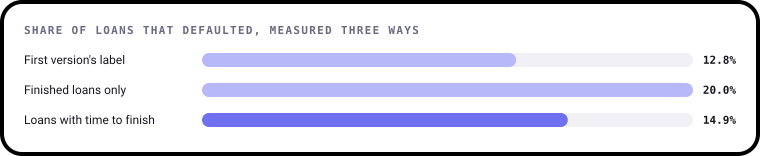

In [4]:
charts.three_answers()

## 2. Grades work

In [5]:
an.by_grade().round(3)

,loans,default_rate,interest,earned_3y,earned_5y
A,144228,0.055,7.225,7.277,13.034
B,220255,0.114,10.896,8.994,15.795
C,180248,0.183,14.077,8.656,19.143
D,87158,0.238,17.290,8.076,18.714
E,32154,0.294,20.121,6.432,20.405
F,10352,0.345,23.254,5.314,19.297
G,2064,0.374,24.309,3.741,19.484


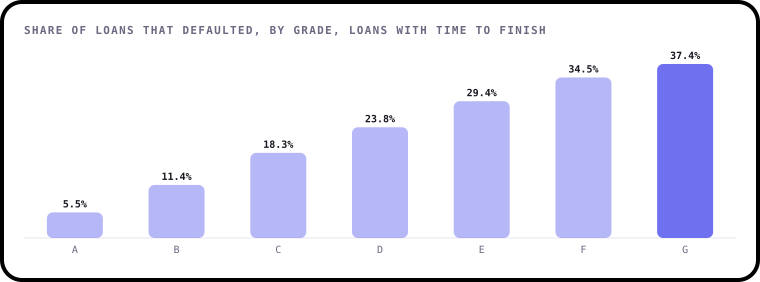

In [6]:
charts.default_by_grade()

## 3. Did the extra interest pay for the extra risk?

`earned_3y` and `earned_5y` are the cents repaid above each dollar lent. They leave out fees and aren't adjusted for time, so the two terms shouldn't be compared directly.

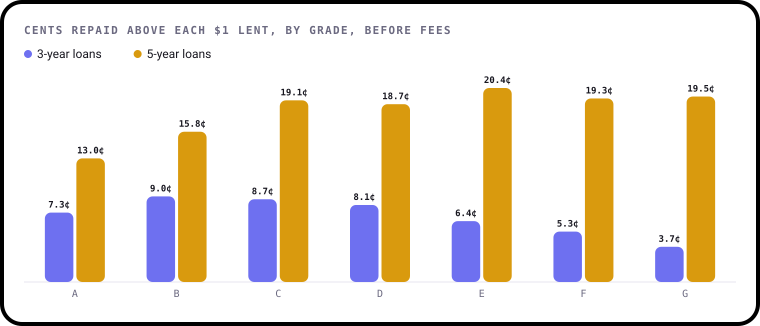

In [7]:
charts.earned_by_grade()

## 4. The same grade got riskier

In [8]:
pd.concat({year: an.three_year_by_grade(year)[["default_rate", "interest"]] for year in (2013, 2015)}, axis=1).round(3)

2013                  2015         
  default_rate interest default_rate interest
A        0.046    7.699        0.054    6.903
B        0.098   11.801        0.119   10.020
C        0.153   15.385        0.194   13.242
D        0.204   18.665        0.262   16.639
E        0.233   21.570        0.328   19.107
F        0.268   23.919        0.424   23.540
G        0.267   25.751        0.461   26.869

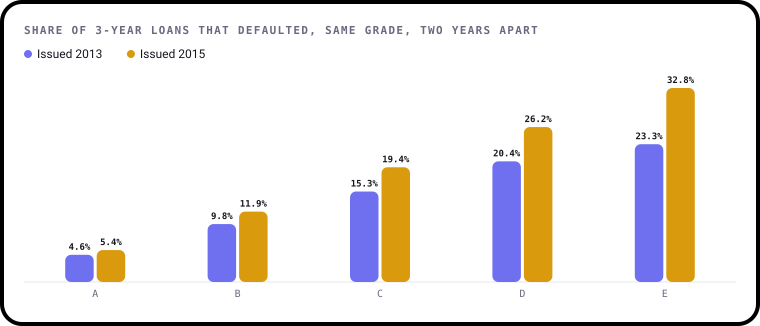

In [9]:
charts.same_grade_worse()

## 5. Income still matters inside a grade

In [10]:
(an.rate_by_band_and_grade("income") * 100).round(1)

,A,B,C,D,E,F,G
$40k to $60k,6.2,11.9,19.3,24.8,31.0,36.7,40.0
$60k to $80k,5.3,10.8,17.5,23.0,30.4,36.6,38.6
$80k to $120k,4.5,9.8,15.5,21.2,26.2,29.8,38.0
Over $120k,4.2,8.8,14.4,19.2,23.7,28.2,27.5
Under $40k,8.4,14.0,20.8,25.9,30.9,36.8,41.3


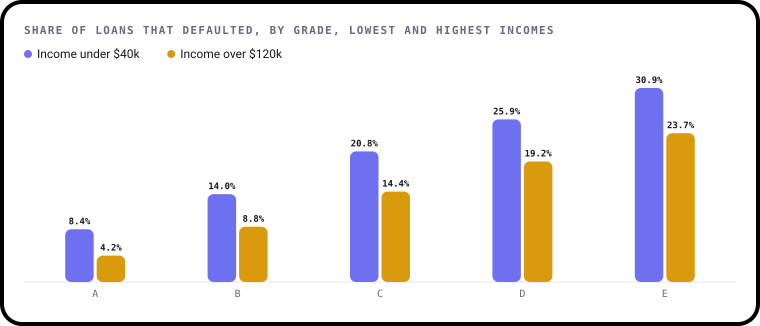

In [11]:
charts.income_within_grade()

Credit score narrows much more once grade is held still, because the grade already leans on it.

In [12]:
(an.rate_by_band_and_grade("fico") * 100).round(1)

,A,B,C,D,E,F,G
680 to 699,6.8,11.7,18.2,23.4,29.5,34.0,36.6
700 to 719,6.0,10.7,16.9,23.0,26.3,32.3,39.6
720 to 749,5.3,10.1,17.0,21.8,28.8,34.6,31.6
750 or more,3.6,9.9,16.1,22.8,26.9,36.8,16.7
Under 680,7.9,12.3,19.1,24.4,30.0,35.0,37.8


## 6. What borrowers say

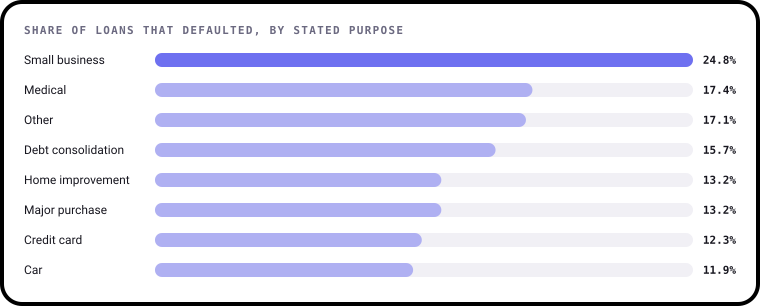

In [13]:
charts.purposes()

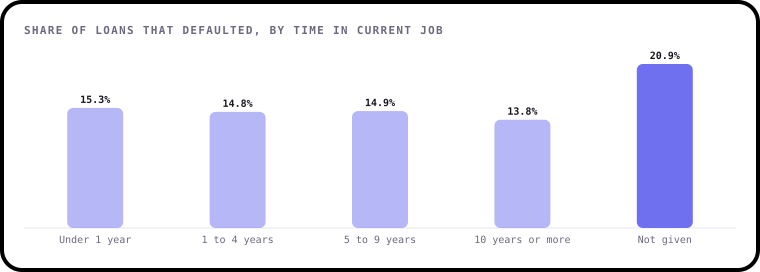

In [14]:
charts.employment()

## 7. Can a model beat the lender's grade?

A fair test only lets a model see the past: train on loans issued up to 2013, test on 3-year loans from 2014 and 2015. The applicant features leave out anything known only after the loan was made, such as repayments.

In [15]:
result = an.models()
print(f"Train on {result['train_size']:,} loans, test on {result['test_size']:,}")
result["auc"].round(3).to_frame("ROC AUC")

Train on 20,471 loans, test on 39,136


,ROC AUC
Lender's sub-grade alone,0.666
Applicant data plus interest rate,0.662
"Applicant data, logistic regression",0.634
"Applicant data, gradient boosting",0.629


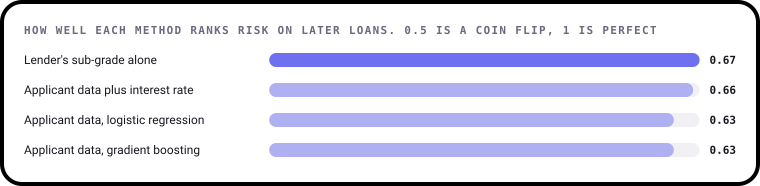

In [16]:
charts.model_scores()

The sub-grade wins, and the gap holds up when the test loans are resampled:

In [17]:
print(f"Sub-grade minus applicant model: {result['gap_low']:.3f} to {result['gap_high']:.3f}")

Sub-grade minus applicant model: 0.024 to 0.040


The lender saw far more data than the columns used here, so this isn't surprising. The model still sorts risk usefully:

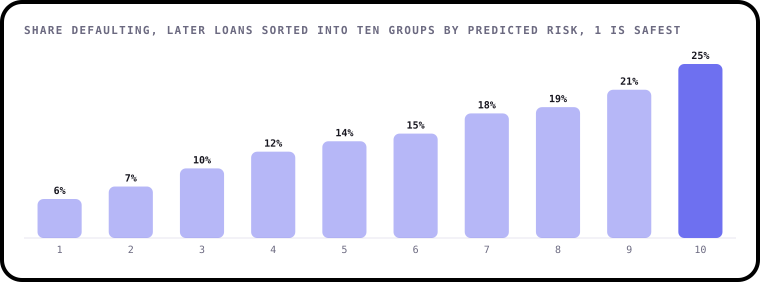

In [18]:
charts.risk_deciles()

## Limits

- Only approved loans appear, so nobody knows what rejected applicants would have done.
- This is one US lender in one period, and the mature loans end before the pandemic.
- The cents-per-dollar figures leave out fees and timing, so they aren't a rate of return.
- Comparisons between groups don't show what causes default.